In [1]:
import pathlib

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

import el_hd_plasticity.connectomics as cn
from el_hd_plasticity.connectomics import plotting
from el_hd_plasticity.connectomics import synapse_distance as sd

plt.rcParams['pdf.fonttype'] = 42

%load_ext autoreload
%autoreload 2
%matplotlib inline

figfolder = pathlib.Path('/media/mplitt/SSD_storage/fig_scratch/EL_connectomics')
figfolder.mkdir(parents=True, exist_ok=True)
syndist_folder = figfolder / 'syn_distances'      # written by el_hd_plasticity.connectomics.run_*synapse_distance
client = cn.npt_client()

## Distance between EL (ER neurons) or DAN (Kenyon cells) input synapses and the nearest output synapse

In [2]:
# distances computed by run_synapse_distance.py and run_mb_synapse_distance.py
kc_df = sd.load_distance_table(syndist_folder, ['kc'], ['dan_post'])
kc_df['er'] = 'kc'
er_df = sd.load_distance_table(syndist_folder, ('ER4d', 'ER2_a', 'ER2_b', 'ER2_c', 'ER2_d', 'ER3p_a', 'ER3p_b'),
                               ('el_post', 'exr2_post'))
print(kc_df['distances'].notna().sum(), 'KC output synapses with a DAN synapse in range')

116833 KC output synapses with a DAN synapse in range


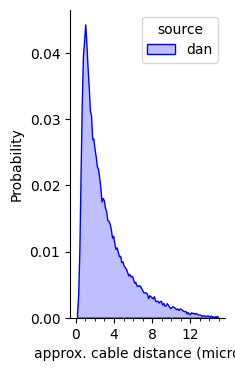

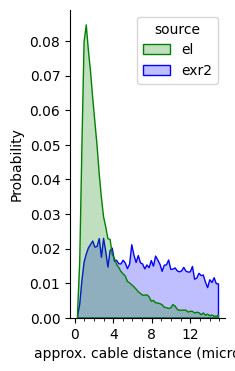

In [3]:
fig, ax = plotting.plot_distance_histogram(kc_df, hue_order=('dan',), palette=('blue',))
fig, ax = plotting.plot_distance_histogram(er_df, hue_order=('el', 'exr2'), palette=('green', 'blue'))

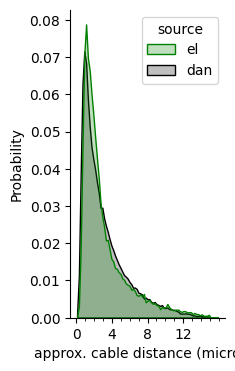

In [4]:
comb_df = pd.concat((er_df, kc_df), ignore_index=True)
fig, ax = plotting.plot_distance_histogram(comb_df, hue_order=('el', 'dan'), palette=('green', 'black'),
                                           bins=np.linspace(0, 16, 80))
fig.savefig(figfolder / 'kc_v_er2_er3p_er4d_syn_distances.pdf')